# Passo 1 – Os dados e a régua de dinheiro

**Pergunta deste passo:** antes de treinar qualquer árvore, *o que conta como sucesso* e *existe dinheiro possível* em cada tamanho de candle?

Ordem de decisões que vamos seguir (do que define o problema para o que só ajusta o modelo):

| Passo | Decisão | Por que nessa ordem |
|---|---|---|
| **1** | Régua de dinheiro + tamanho de candle viável | Sem saber como medimos lucro, nenhuma comparação faz sentido |
| 2 | Alvo: o que a árvore prevê | Define a pergunta que o modelo responde |
| 3 | Variáveis: o que a árvore vê | Só informação disponível no instante t |
| 4 | Candle × janela de treino | Quanto histórico o modelo usa para aprender |
| 5 | Regra de operação (quando entrar) | Transforma previsão em ordem |
| 6 | Hiperparâmetros (profundidade, folha) | Ajuste fino: vem por último |
| 7 | Teste final (uma vez) | Tudo congelado |
| 8 | Repetir para o dólar (WDO) | Mesmo roteiro |


In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import rf_zero as rz
PASTA_DADOS = "../../dados"
win_1m = rz.carregar(f"{PASTA_DADOS}/WINN_M1/WIN$N_M1.csv")
print(win_1m.index.min(), "→", win_1m.index.max(), "|", len(win_1m), "candles de 1 min no pregão regular")
win_1m.head()

2020-10-15 11:49:00 → 2026-09-25 17:59:00 | 733513 candles de 1 min no pregão regular


,open,high,low,close,tickvol,vol
2020-10-15 11:49:00,98565,98575,98530,98575,2373,9001
2020-10-15 11:50:00,98570,98625,98570,98600,5483,19111
2020-10-15 11:51:00,98595,98600,98535,98580,4572,17663
2020-10-15 11:52:00,98575,98620,98535,98615,3536,13143
2020-10-15 11:53:00,98620,98625,98575,98610,3729,13702


## 1.1 A régua de dinheiro

Cada candle *t* o modelo escolhe uma de três ações: **comprar (+1)**, **vender (−1)** ou **ficar de fora (0)**.
Quem opera entra no fechamento de *t* e sai no fechamento de *t+1*:

$$	ext{resultado (pts)} = 	ext{direção} 	imes (	ext{close}_{t+1} - 	ext{close}_t) - 	ext{custo}$$

* **Custo = 5 pontos** por operação (ida + volta). No WIN, 1 ponto = R$ 0,20 por contrato.
* Não levamos posição de um dia para o outro (o último candle do dia não opera).

**Critério do "melhor cenário"** (vale para todos os passos seguintes, sempre medido na validação 2024):
1. **Esperança por operação** (pts, já com custo) > 0 → cada operação, em média, ganha dinheiro;
2. **Estatística t** da esperança ≥ 2 → o ganho não é sorte;
3. **Consistência**: positivo em pelo menos 3 dos 4 trimestres de 2024;
4. Desempate: **lucro total** em pontos (esperança × nº de operações).

> Por que não "taxa de acerto"? Acertar 55% das vezes ganhando 2 pts e errar 45% perdendo 10 pts dá prejuízo. O que paga a conta é a esperança.

In [2]:
def resumo(res_pts):
    """Resumo padrão de um conjunto de operações (pts, já com custo)."""
    res_pts = np.asarray(res_pts)
    n = len(res_pts)
    if n < 2:
        return pd.Series({"n_ops": n, "esperanca_pts": np.nan, "t": np.nan, "acerto_%": np.nan, "total_pts": res_pts.sum()})
    esp = res_pts.mean()
    t = esp / (res_pts.std(ddof=1) / np.sqrt(n))
    return pd.Series({"n_ops": n, "esperanca_pts": esp, "t": t,
                      "acerto_%": 100 * (res_pts > 0).mean(), "total_pts": res_pts.sum()})

## 1.2 A separação do tempo (mantida do projeto)

Nunca embaralhamos: o modelo só aprende com o passado e é avaliado no futuro.

In [3]:
base = rz.adicionar_alvo(win_1m)
partes = {"treino (até 2023)": base[base.index < rz.VALIDACAO[0]],
          "validação (2024)": rz.periodo(base, rz.VALIDACAO),
          "teste (01/25–03/26)": rz.periodo(base, rz.TESTE),
          "extra (04/26–09/26)": rz.periodo(base, rz.EXTRA)}
pd.DataFrame({k: {"início": v.index.min().date(), "fim": v.index.max().date(),
                  "candles 1 min": len(v), "pregões": v.index.normalize().nunique()}
              for k, v in partes.items()}).T

,início,fim,candles 1 min,pregões
treino (até 2023),2020-10-15,2023-12-28,365104,683
validação (2024),2024-01-02,2024-12-30,135280,251
teste (01/25–03/26),2025-01-02,2026-03-31,167136,311
extra (04/26–09/26),2026-04-01,2026-09-25,65993,123


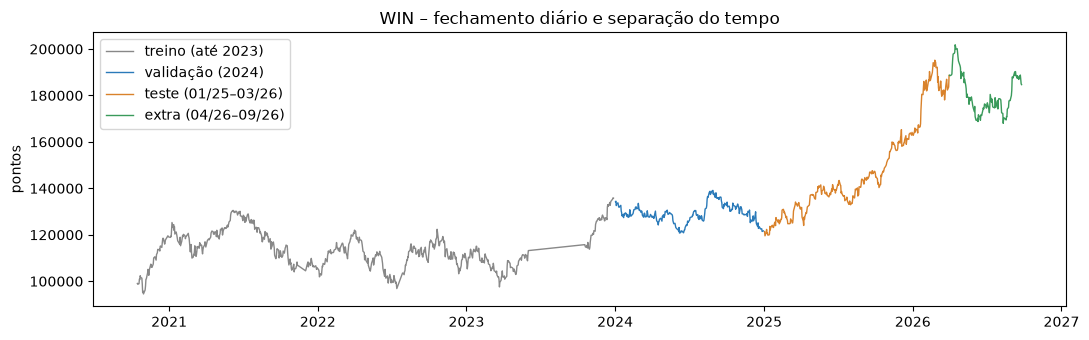

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.5))
cores = ["#888", "#2a7ab9", "#d9822b", "#3a9a5b"]
for (nome, p), c in zip(partes.items(), cores):
    d = p["close"].resample("D").last().dropna()
    ax.plot(d.index, d.values, color=c, label=nome, lw=1)
ax.set_title("WIN – fechamento diário e separação do tempo"); ax.set_ylabel("pontos"); ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig("passo01_separacao.png", dpi=120); plt.show()

## 1.3 Existe dinheiro possível em cada tamanho de candle?

O custo é fixo (5 pts), mas o tamanho do movimento cresce com o candle. Se o candle se mexe pouco, nem acertando a direção dá para pagar o custo.

Medimos **no período de treino** (para não "espiar" a validação):
* **movimento típico**: mediana de |close<sub>t+1</sub> − close<sub>t</sub>|;
* **% de candles que pagam o custo**: |movimento| > 5 pts;
* **teto teórico**: esperança de um "oráculo" que acerta 100% das direções;
* **acerto mínimo necessário**: que taxa de acerto um modelo precisaria, com ganhos e perdas do tamanho típico, para empatar após o custo.

In [5]:
CANDLES = [1, 5, 15, 30, 60]
treino_1m = win_1m[win_1m.index < rz.VALIDACAO[0]]
linhas = {}
for m in CANDLES:
    b = rz.adicionar_alvo(rz.reamostrar(treino_1m, m)).dropna(subset=["mov_prox"])
    mov = b["mov_prox"].values
    a = np.abs(mov)
    oraculo = rz.resultado_operacoes(np.sign(mov), mov)          # acerta tudo
    sempre_compra = rz.resultado_operacoes(np.ones_like(mov), mov)
    # acerto p tal que p*E|mov| - (1-p)*E|mov| - custo = 0  ->  p = (1 + custo/E|mov|)/2
    p_min = (1 + rz.CUSTO_PTS / a.mean()) / 2
    linhas[f"{m} min"] = {"candles": len(b), "candles/dia": round(len(b) / b.index.normalize().nunique()),
                          "mov. típico (pts)": np.median(a), "mov. médio (pts)": a.mean(),
                          "% que paga custo": 100 * (a > rz.CUSTO_PTS).mean(),
                          "custo / mov. médio": rz.CUSTO_PTS / a.mean(),
                          "acerto mínimo p/ empatar %": 100 * p_min,
                          "oráculo pts/op": oraculo.mean(), "sempre compra pts/op": sempre_compra.mean()}
viab = pd.DataFrame(linhas).T
viab.round(2)

,candles,candles/dia,mov. típico (pts),mov. médio (pts),% que paga custo,custo / mov. médio,acerto mínimo p/ empatar %,oráculo pts/op,sempre compra pts/op
1 min,364421.0,534.0,30.0,40.85,85.41,0.12,56.12,37.95,-5.01
5 min,72372.0,106.0,65.0,92.02,93.87,0.05,52.72,88.90,-4.98
15 min,23807.0,35.0,115.0,157.28,96.40,0.03,51.59,154.13,-4.73
30 min,11563.0,17.0,160.0,224.15,97.28,0.02,51.12,221.07,-4.50
60 min,5441.0,8.0,235.0,323.36,98.07,0.02,50.77,320.51,-4.63


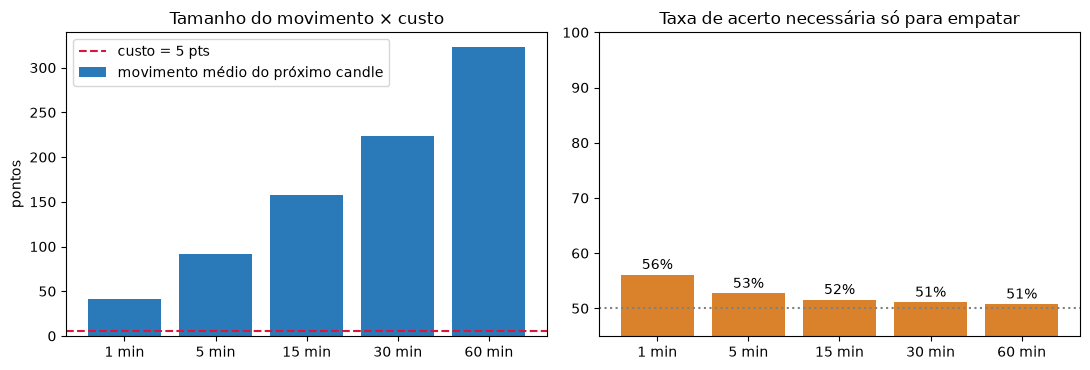

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
x = viab.index
axs[0].bar(x, viab["mov. médio (pts)"], color="#2a7ab9", label="movimento médio do próximo candle")
axs[0].axhline(rz.CUSTO_PTS, color="crimson", ls="--", label=f"custo = {rz.CUSTO_PTS} pts")
axs[0].set_title("Tamanho do movimento × custo"); axs[0].set_ylabel("pontos"); axs[0].legend()
axs[1].bar(x, viab["acerto mínimo p/ empatar %"], color="#d9822b")
axs[1].axhline(50, color="gray", ls=":")
axs[1].set_ylim(45, 100); axs[1].set_title("Taxa de acerto necessária só para empatar")
for i, v in enumerate(viab["acerto mínimo p/ empatar %"]):
    axs[1].text(i, v + 1, f"{v:.0f}%", ha="center")
plt.tight_layout(); plt.savefig("passo01_viabilidade.png", dpi=120); plt.show()

## Conclusões do Passo 1

1. **Separação do tempo:** treino até 2023 (683 pregões), validação 2024 (251), teste 01/2025–03/2026 (311) e um período extra 04–09/2026 (123) que nunca entra em escolha nenhuma.
2. **"Sempre compra" perde ≈ 5 pts/op**: sem previsão, o resultado é só o custo. Este é o piso que o modelo precisa superar.
3. **O custo pesa muito mais no candle de 1 min**: o movimento médio é 41 pts, o custo (5) é 12% dele, e o modelo precisaria acertar **56%** das direções só para empatar. No candle de 15 min o custo é 3% do movimento e bastam **51,6%**; no de 60 min, **50,8%**.
4. **Mas candles maiores dão menos exemplos**: 534 candles/dia em 1 min contra 8 em 60 min. Menos exemplos = árvore aprende com menos dados e a validação tem menos operações (estatística t mais fraca).

➡️ Esse é o dilema que o **Passo 4** (candle × janela de treino) vai resolver com dados. Por ora levamos adiante **5, 15, 30 e 60 min**; o 1 min fica como referência (já sabemos que ele exige 56% de acerto, muito difícil).


In [7]:
viab[["mov. médio (pts)", "custo / mov. médio", "acerto mínimo p/ empatar %"]].round(1)

,mov. médio (pts),custo / mov. médio,acerto mínimo p/ empatar %
1 min,40.8,0.1,56.1
5 min,92.0,0.1,52.7
15 min,157.3,0.0,51.6
30 min,224.2,0.0,51.1
60 min,323.4,0.0,50.8
